# Deep-dive Stage 5/5 -- final fine-tune, test evaluation, embeddings

Part 5 of 5. Loads every winner from Stages 1-4's checkpoint, re-trains that fully-
winning combo for longer, and **only now** evaluates on **test** -- reporting the full
metric suite (val + test accuracy, macro-F1, per-class report, confusion matrices,
train/val curves). Then extracts and saves the final model's embeddings for the fusion
notebook.


In [1]:
# ============================================================
# 1. CONFIG -- EDIT THESE FOR YOUR KAGGLE NOTEBOOK
# ============================================================
from pathlib import Path
import json as _json

# --- INPUTS: attach BOTH datasets to this notebook (Add Input -> Datasets, twice) --
# the plain patient-level split AND the augmented one -- needed again in every stage's
# notebook, since each stage re-trains from scratch.
SPLIT_ROOT_ORIGINAL = Path("/kaggle/input/datasets/gokulkrishnabr/segmented-zenodo/train test vali zenodo")
SPLIT_ROOT_AUGMENTED = Path("/kaggle/input/datasets/gokulkrishnabr/augmented-zenodo/augmented_dataset")
for _root in (SPLIT_ROOT_ORIGINAL, SPLIT_ROOT_AUGMENTED):
    for _s in ("train", "val", "test"):
        assert (_root / _s).is_dir(), f"{_root / _s} not found -- fix the paths above."

DATA_VARIANTS = {"original": SPLIT_ROOT_ORIGINAL, "augmented": SPLIT_ROOT_AUGMENTED}
LOSS_VARIANTS = {"unweighted": False, "weighted": True}

OUTPUT_DIR = Path("/kaggle/working")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_OUTPUT = OUTPUT_DIR / "checkpoint.json"

# --- CHECKPOINT: attach the PREVIOUS stage's Output as a third dataset input, then
# fix this path to point at its checkpoint.json.
CHECKPOINT_INPUT = Path("/kaggle/input/datasets/gokulkrishnabr/json-stage4-results/checkpoint.json")
assert CHECKPOINT_INPUT.is_file(), (
    f"{CHECKPOINT_INPUT} not found -- attach stage4's Output dataset and fix this path.")
_ckpt = _json.loads(CHECKPOINT_INPUT.read_text())
print("Loaded checkpoint from stage4:")
for _k, _v in _ckpt.items():
    print(f"  {_k} = {_v}")

BACKBONE_KEY = _ckpt["BACKBONE_KEY"]
BEST_PHASE2_LR = _ckpt["BEST_PHASE2_LR"]

BEST_DATA_VARIANT = _ckpt["BEST_DATA_VARIANT"]
BEST_LOSS_VARIANT = _ckpt["BEST_LOSS_VARIANT"]
BEST_DROPOUT = _ckpt["BEST_DROPOUT"]
BEST_WEIGHT_DECAY = _ckpt["BEST_WEIGHT_DECAY"]
BEST_OPTIMIZER = _ckpt["BEST_OPTIMIZER"]
BEST_BATCH_SIZE = _ckpt["BEST_BATCH_SIZE"]
BEST_HEAD_ARCH = _ckpt["BEST_HEAD_ARCH"]

IMG_SIZE = 224
BATCH_SIZE = 32
PHASE1_LR = 1e-3
RANDOM_SEED = 42

GRID_PHASE1_EPOCHS = 8
GRID_PHASE2_EPOCHS = 12
GRID_EARLY_STOP_PATIENCE = 4

USE_RUNTIME_AUGMENTATION = True
LABEL_SMOOTHING = 0.1
REDUCE_LR_FACTOR = 0.5
REDUCE_LR_PATIENCE = 3

BACKBONES = {
    "mobilenetv2": dict(title="MobileNetV2", keras_class="MobileNetV2",
                         module="keras.applications.mobilenet_v2", needs_manual_preprocess=True),
    "mobilenetv3small": dict(title="MobileNetV3-Small", keras_class="MobileNetV3Small",
                              module="keras.applications.mobilenet_v3", needs_manual_preprocess=False),
    "efficientnetb0": dict(title="EfficientNetB0", keras_class="EfficientNetB0",
                            module="keras.applications.efficientnet", needs_manual_preprocess=False),
    "efficientnetv2b0": dict(title="EfficientNetV2B0", keras_class="EfficientNetV2B0",
                              module="keras.applications.efficientnet_v2", needs_manual_preprocess=False),
}

FINAL_PHASE1_EPOCHS = 30
FINAL_PHASE2_EPOCHS = 70
FINAL_EARLY_STOP_PATIENCE = 15

assert BACKBONE_KEY in BACKBONES, f"BACKBONE_KEY must be one of {list(BACKBONES)}"
BB = BACKBONES[BACKBONE_KEY]
print("\nBackbone            :", BB["title"])
print("Best Phase-2 LR      :", BEST_PHASE2_LR)
print("Output folder        :", OUTPUT_DIR)

print("\nFully-winning combo:")
for _k in ("BEST_DATA_VARIANT","BEST_LOSS_VARIANT","BEST_DROPOUT","BEST_WEIGHT_DECAY","BEST_OPTIMIZER","BEST_BATCH_SIZE","BEST_HEAD_ARCH"):
    print(f"  {_k} = {globals()[_k]}")


Loaded checkpoint from stage4:
  BACKBONE_KEY = efficientnetb0
  BEST_PHASE2_LR = 0.0001
  BEST_DATA_VARIANT = augmented
  BEST_LOSS_VARIANT = weighted
  BEST_DROPOUT = 0.5
  BEST_WEIGHT_DECAY = 0.0
  BEST_OPTIMIZER = adam
  BEST_BATCH_SIZE = 32
  BEST_HEAD_ARCH = plain

Backbone            : EfficientNetB0
Best Phase-2 LR      : 0.0001
Output folder        : /kaggle/working

Fully-winning combo:
  BEST_DATA_VARIANT = augmented
  BEST_LOSS_VARIANT = weighted
  BEST_DROPOUT = 0.5
  BEST_WEIGHT_DECAY = 0.0
  BEST_OPTIMIZER = adam
  BEST_BATCH_SIZE = 32
  BEST_HEAD_ARCH = plain


In [2]:
# ============================================================
# 2. IMPORTS + HELPERS (dataset builder, class-weight helper, model/optimizer builders,
#    eval, and a reusable curve-plotting helper for every tuning stage)
# ============================================================
import time
import gc
import json as _json
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.utils.class_weight import compute_class_weight

print("TensorFlow:", tf.__version__, " Keras:", keras.__version__)
tf.random.set_seed(RANDOM_SEED)

_backbone_module = importlib.import_module(BB["module"])
BACKBONE_CLASS = getattr(keras.applications, BB["keras_class"])
if BB["needs_manual_preprocess"]:
    _preprocess_input = getattr(_backbone_module, "preprocess_input")
    def preprocess(x, y):
        return _preprocess_input(x), y
else:
    def preprocess(x, y):
        return x, y   # this backbone's preprocessing is built in (include_preprocessing=True)

# --- Light, clinically-safe runtime augmentation -- applied to the TRAIN split only,
# on every run below, regardless of which Stage-1 data variant is in use. This is a
# separate, additional overfitting countermeasure from the offline OCA-oversampling
# done by the augmentation notebook (which only changes the "augmented" data variant):
# this one runs on-the-fly, on EVERY training image of EITHER variant, so it can't bias
# the Stage-1 original-vs-augmented comparison (both get it identically). Only the same
# safe transform families used by the offline augmentation notebook are used here --
# no vertical flip, no hue shift, no heavy distortion -- since those can misrepresent a
# lesion clinically.
_runtime_augmenter = keras.Sequential([
    keras.layers.RandomFlip("horizontal"),
    keras.layers.RandomRotation(0.04),     # ~+-15 degrees
    keras.layers.RandomZoom(0.1),
    keras.layers.RandomContrast(0.1),
], name="runtime_augmentation")


def build_datasets(split_root, batch_size=None, augment_train=None):
    '''Loads train/val/test folder-per-class datasets from split_root, returns the
    preprocessed tf.data pipelines plus the raw (unbatched-friendly) train dataset used
    for computing class weights. batch_size defaults to the global BATCH_SIZE, but stage
    3 (optimizer x batch size) overrides it per cell. augment_train defaults to the
    global USE_RUNTIME_AUGMENTATION flag; val/test are NEVER augmented.'''
    bs = batch_size or BATCH_SIZE
    do_augment = USE_RUNTIME_AUGMENTATION if augment_train is None else augment_train
    train_raw = keras.utils.image_dataset_from_directory(
        split_root / "train", image_size=(IMG_SIZE, IMG_SIZE), batch_size=bs,
        label_mode="categorical", shuffle=True, seed=RANDOM_SEED)
    val_raw = keras.utils.image_dataset_from_directory(
        split_root / "val", image_size=(IMG_SIZE, IMG_SIZE), batch_size=bs,
        label_mode="categorical", shuffle=False)
    test_raw = keras.utils.image_dataset_from_directory(
        split_root / "test", image_size=(IMG_SIZE, IMG_SIZE), batch_size=bs,
        label_mode="categorical", shuffle=False)
    class_names = train_raw.class_names
    assert val_raw.class_names == class_names and test_raw.class_names == class_names, (
        f"Class folder names differ between train/val/test under {split_root}")
    if do_augment:
        train_ds = train_raw.map(lambda x, y: (_runtime_augmenter(x, training=True), y)).map(
            preprocess).prefetch(tf.data.AUTOTUNE)
    else:
        train_ds = train_raw.map(preprocess).prefetch(tf.data.AUTOTUNE)
    val_ds = val_raw.map(preprocess).prefetch(tf.data.AUTOTUNE)
    test_ds = test_raw.map(preprocess).prefetch(tf.data.AUTOTUNE)
    return train_ds, val_ds, test_ds, train_raw, class_names


def class_weight_for(train_raw, n_classes, weighted):
    if not weighted:
        return None
    labels = np.array([int(tf.argmax(y).numpy()) for _, y in train_raw.unbatch()])
    w = compute_class_weight("balanced", classes=np.arange(n_classes), y=labels)
    return {i: v for i, v in enumerate(w)}


def make_optimizer(lr, weight_decay, optimizer_name):
    '''Decoupled weight decay via Keras 3's built-in `weight_decay` kwarg -- 0.0 is a
    valid value and simply disables it, so the same call works for every grid cell.'''
    if optimizer_name == "adam":
        return keras.optimizers.Adam(lr, weight_decay=weight_decay)
    if optimizer_name == "sgd":
        return keras.optimizers.SGD(lr, momentum=0.9, weight_decay=weight_decay)
    if optimizer_name == "rmsprop":
        return keras.optimizers.RMSprop(lr, weight_decay=weight_decay)
    raise ValueError(f"Unknown optimizer_name: {optimizer_name!r}")


def build_fresh_model(n_classes, dropout_rate=0.3, head_arch="plain"):
    '''A brand-new model with fresh ImageNet weights -- called once per grid cell so no
    fine-tuning from a previous combo leaks into the next one. head_arch controls the
    classification head on top of the pooled backbone features:
      "plain"           -- dropout -> dense(n_classes)                 (Stage A's head)
      "wide_relu"       -- dense(128, relu) -> dropout -> dense(n_classes)
      "wide_leaky_relu" -- dense(128) -> LeakyReLU(0.1) -> dropout -> dense(n_classes)
    '''
    base_model = BACKBONE_CLASS(
        include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3), pooling="avg")
    base_model.trainable = False
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    features = base_model(inputs, training=False)
    if head_arch == "plain":
        x = keras.layers.Dropout(dropout_rate, name="head_dropout")(features)
    elif head_arch == "wide_relu":
        x = keras.layers.Dense(128, activation="relu", name="head_dense_wide")(features)
        x = keras.layers.Dropout(dropout_rate, name="head_dropout")(x)
    elif head_arch == "wide_leaky_relu":
        x = keras.layers.Dense(128, name="head_dense_wide")(features)
        try:
            x = keras.layers.LeakyReLU(negative_slope=0.1, name="head_leaky_relu")(x)
        except TypeError:
            x = keras.layers.LeakyReLU(alpha=0.1, name="head_leaky_relu")(x)   # older Keras
        x = keras.layers.Dropout(dropout_rate, name="head_dropout")(x)
    else:
        raise ValueError(f"Unknown head_arch: {head_arch!r}")
    outputs = keras.layers.Dense(n_classes, activation="softmax", name="head_dense_out")(x)
    model = keras.Model(inputs, outputs, name=f"{BACKBONE_KEY}_tuned")
    return model, base_model, features


def evaluate_split(model, ds, n_classes, class_names):
    y_true, y_pred = [], []
    for xb, yb in ds:
        preds = model.predict(xb, verbose=0)
        y_true.extend(np.argmax(yb.numpy(), axis=1))
        y_pred.extend(np.argmax(preds, axis=1))
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    acc = float((y_true == y_pred).mean())
    macro_f1 = f1_score(y_true, y_pred, average="macro")
    report = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)
    return acc, macro_f1, report, y_true, y_pred


def free_run_memory(result):
    '''Drops the GPU-resident model/base_model from a train_two_phase result once
    you're done evaluating it, keeping only the lightweight (CPU-side) history dicts
    for the curve plots. This matters a lot here: this notebook trains 15+ models in
    sequence within ONE long-running process, and Keras/TensorFlow does not
    automatically free a model's allocated GPU memory just because Python no longer
    holds a reference to it -- without an explicit clear_session()+gc.collect() between
    every grid cell, memory from every earlier cell's model can pile up and eventually
    exhaust the GPU, even though any single cell's model is small on its own.'''
    result.pop("model", None)
    result.pop("base_model", None)
    result.pop("features", None)
    keras.backend.clear_session()
    gc.collect()
    return result


def plot_grid_curves(cell_results, cell_labels, title, save_path):
    '''One row per grid cell: train/val accuracy (left) and train/val loss (right),
    phase 1 and phase 2 both shown, with a dashed line marking the phase1->phase2
    switch -- this is what makes each cell's overfitting behavior visible, not just
    its final number.'''
    n = len(cell_results)
    fig, axes = plt.subplots(n, 2, figsize=(11, 3.0 * n), squeeze=False)
    for row, (result, label) in enumerate(zip(cell_results, cell_labels)):
        h1, h2 = result["hist1"].history, result["hist2"].history
        n1 = len(h1["accuracy"])
        ep1 = range(1, n1 + 1)
        ep2 = range(n1 + 1, n1 + len(h2["accuracy"]) + 1)
        ax_acc, ax_loss = axes[row]
        ax_acc.plot(ep1, h1["accuracy"], label="train p1", color="#7fb3ff")
        ax_acc.plot(ep1, h1["val_accuracy"], label="val p1", color="#08306b")
        ax_acc.plot(ep2, h2["accuracy"], label="train p2", color="#ffb27f")
        ax_acc.plot(ep2, h2["val_accuracy"], label="val p2", color="#8c2d04")
        ax_acc.axvline(n1 + 0.5, color="gray", ls="--", lw=1)
        ax_acc.set_title(f"{label} -- accuracy", fontsize=9)
        ax_acc.legend(fontsize=6, ncol=2)
        ax_loss.plot(ep1, h1["loss"], label="train p1", color="#7fb3ff")
        ax_loss.plot(ep1, h1["val_loss"], label="val p1", color="#08306b")
        ax_loss.plot(ep2, h2["loss"], label="train p2", color="#ffb27f")
        ax_loss.plot(ep2, h2["val_loss"], label="val p2", color="#8c2d04")
        ax_loss.axvline(n1 + 0.5, color="gray", ls="--", lw=1)
        ax_loss.set_title(f"{label} -- loss", fontsize=9)
        ax_loss.legend(fontsize=6, ncol=2)
    fig.suptitle(title)
    plt.tight_layout()
    fig.savefig(save_path, dpi=130, bbox_inches="tight")
    plt.show()


TensorFlow: 2.20.0  Keras: 3.13.2


I0000 00:00:1790873416.107275      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790873416.111206      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [3]:
# ============================================================
# 3. ONE TWO-PHASE TRAINING RUN (reused by every tuning stage and the final run)
# ============================================================
def train_two_phase(run_name, train_ds, val_ds, class_weight, n_classes,
                     phase1_epochs, phase2_epochs, phase2_lr,
                     dropout_rate=0.3, weight_decay=0.0, optimizer_name="adam", head_arch="plain",
                     early_stop_patience=None):
    patience = GRID_EARLY_STOP_PATIENCE if early_stop_patience is None else early_stop_patience
    model, base_model, features = build_fresh_model(n_classes, dropout_rate=dropout_rate, head_arch=head_arch)
    p1_weights = OUTPUT_DIR / f"{run_name}_phase1.weights.h5"
    p2_weights = OUTPUT_DIR / f"{run_name}_phase2.weights.h5"

    _loss = keras.losses.CategoricalCrossentropy(label_smoothing=LABEL_SMOOTHING)

    model.compile(optimizer=make_optimizer(PHASE1_LR, weight_decay, optimizer_name),
                  loss=_loss, metrics=["accuracy"])
    cb1 = [
        keras.callbacks.ModelCheckpoint(str(p1_weights), save_best_only=True,
                                         save_weights_only=True, monitor="val_accuracy", mode="max"),
        keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max",
                                       patience=patience, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", mode="min",
                                           factor=REDUCE_LR_FACTOR, patience=REDUCE_LR_PATIENCE,
                                           min_lr=1e-7),
    ]
    hist1 = model.fit(train_ds, validation_data=val_ds, epochs=phase1_epochs,
                       class_weight=class_weight, callbacks=cb1, verbose=0)
    model.load_weights(str(p1_weights))
    phase1_val_acc = max(hist1.history["val_accuracy"])

    base_model.trainable = True
    model.compile(optimizer=make_optimizer(phase2_lr, weight_decay, optimizer_name),
                  loss=_loss, metrics=["accuracy"])
    cb2 = [
        keras.callbacks.ModelCheckpoint(str(p2_weights), save_best_only=True,
                                         save_weights_only=True, monitor="val_accuracy", mode="max"),
        keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max",
                                       patience=patience, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", mode="min",
                                           factor=REDUCE_LR_FACTOR, patience=REDUCE_LR_PATIENCE,
                                           min_lr=1e-7),
    ]
    hist2 = model.fit(train_ds, validation_data=val_ds, epochs=phase2_epochs,
                       class_weight=class_weight, callbacks=cb2, verbose=0)
    phase2_val_acc = max(hist2.history["val_accuracy"]) if hist2.history["val_accuracy"] else -1

    if phase2_val_acc >= phase1_val_acc:
        model.load_weights(str(p2_weights))
        winning_phase = "phase2 (fine-tuned)"
        best_idx = int(np.argmax(hist2.history["val_accuracy"]))
        train_acc_at_best = hist2.history["accuracy"][best_idx]
        val_acc_at_best = hist2.history["val_accuracy"][best_idx]
    else:
        model.load_weights(str(p1_weights))
        winning_phase = "phase1 (frozen)"
        best_idx = int(np.argmax(hist1.history["val_accuracy"]))
        train_acc_at_best = hist1.history["accuracy"][best_idx]
        val_acc_at_best = hist1.history["val_accuracy"][best_idx]

    return dict(model=model, base_model=base_model, features=features,
                winning_phase=winning_phase, hist1=hist1, hist2=hist2,
                train_accuracy=train_acc_at_best, train_val_gap=train_acc_at_best - val_acc_at_best,
                p1_weights=p1_weights, p2_weights=p2_weights)


Found 2237 files belonging to 4 classes.
Found 517 files belonging to 4 classes.
Found 550 files belonging to 4 classes.
Final run: data=augmented  loss=weighted  dropout=0.5  weight_decay=0.0  optimizer=adam  batch_size=32  head=plain  epochs=(30, 70)
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


2026-10-01 16:53:03.369789: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-01 16:53:03.512828: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-01 16:53:03.861650: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-01 16:53:04.003019: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-01 16:53:04.799148: E external/local_xla/xla/stream_

\nFinal model -- winning checkpoint: phase2 (fine-tuned)
Train accuracy at that checkpoint : 0.9222
Train/val accuracy gap            : 0.3323  (lower = less overfitting)
Final VAL  : accuracy=0.5899  macro_f1=0.4641
Final TEST : accuracy=0.5600  macro_f1=0.5014   <-- key number to report
\nVAL classification report:
              precision    recall  f1-score   support

      Benign       0.56      0.57      0.56       128
     Healthy       0.51      0.69      0.58       123
         OCA       0.06      0.06      0.06        16
        OPMD       0.72      0.58      0.65       250

    accuracy                           0.59       517
   macro avg       0.46      0.48      0.46       517
weighted avg       0.61      0.59      0.59       517

\nTEST classification report:
              precision    recall  f1-score   support

      Benign       0.45      0.50      0.48       128
     Healthy       0.49      0.71      0.58       125
         OCA       0.40      0.27      0.32        37

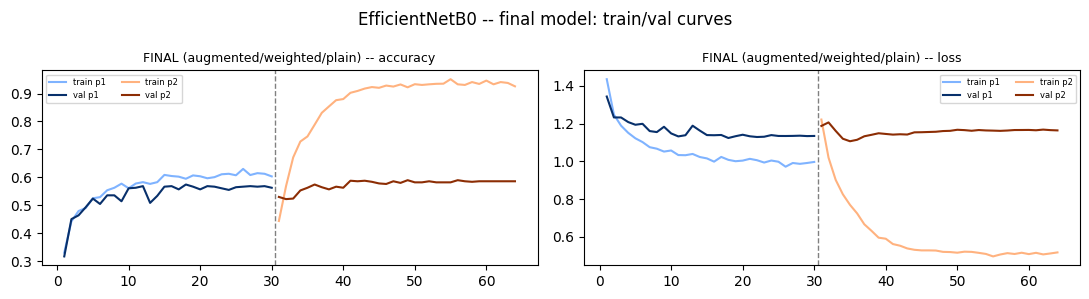

\nFinal run -- epoch-by-epoch accuracy (full table saved to efficientnetb0_final_epoch_history.csv; every 10th epoch + last shown below):
 epoch  phase train_accuracy val_accuracy
    10      1          56.1%       56.09%
    20      1         60.39%       55.71%
    30      1         60.35%       56.29%
    40      2         88.02%       56.29%
    50      2         93.34%       58.22%
    60      2         94.64%       58.61%
    64      2         92.58%       58.61%
\nNote: train_accuracy climbing toward ~98-100% while val_accuracy stays far below it is the overfitting signature flagged throughout this notebook -- a high train-accuracy number alone (like the epoch table above) is not evidence the model generalizes; always read it next to val/test accuracy, not on its own.


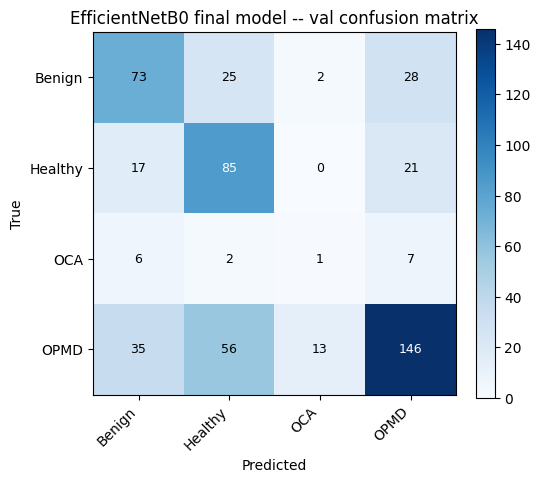

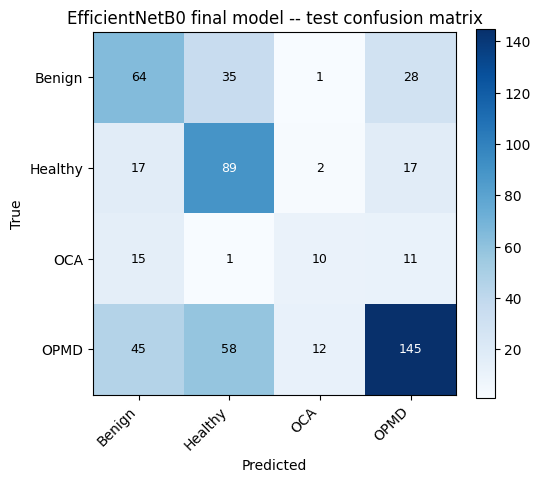

\nSaved final metrics to: /kaggle/working/efficientnetb0_final_metrics.json


In [4]:
# ============================================================
# 13. FINAL, LONGER FINE-TUNE ON THE FULLY-WINNING COMBO -- test set evaluated ONLY here
#     Uses every BEST_* chosen in Stages 1-4. Reports the full Stage-A-style metric
#     suite for BOTH val and test: accuracy, macro-F1, per-class classification report,
#     confusion matrix, and train/val curves (so the train/val gap stays visible).
# ============================================================
final_split_root = DATA_VARIANTS[BEST_DATA_VARIANT]
final_train_ds, final_val_ds, final_test_ds, final_train_raw, FINAL_CLASS_NAMES = build_datasets(
    final_split_root, batch_size=BEST_BATCH_SIZE)
FINAL_N_CLASSES = len(FINAL_CLASS_NAMES)
final_class_weight = class_weight_for(final_train_raw, FINAL_N_CLASSES, LOSS_VARIANTS[BEST_LOSS_VARIANT])

print(f"Final run: data={BEST_DATA_VARIANT}  loss={BEST_LOSS_VARIANT}  dropout={BEST_DROPOUT}  "
      f"weight_decay={BEST_WEIGHT_DECAY}  optimizer={BEST_OPTIMIZER}  batch_size={BEST_BATCH_SIZE}  "
      f"head={BEST_HEAD_ARCH}  epochs=({FINAL_PHASE1_EPOCHS}, {FINAL_PHASE2_EPOCHS})")
t_final0 = time.time()
final_run_name = f"{BACKBONE_KEY}_final_{BEST_DATA_VARIANT}_{BEST_LOSS_VARIANT}_{BEST_HEAD_ARCH}"
final_result = train_two_phase(final_run_name, final_train_ds, final_val_ds, final_class_weight,
                                FINAL_N_CLASSES, FINAL_PHASE1_EPOCHS, FINAL_PHASE2_EPOCHS, BEST_PHASE2_LR,
                                dropout_rate=BEST_DROPOUT, weight_decay=BEST_WEIGHT_DECAY,
                                optimizer_name=BEST_OPTIMIZER, head_arch=BEST_HEAD_ARCH,
                                early_stop_patience=FINAL_EARLY_STOP_PATIENCE)
final_training_minutes = (time.time() - t_final0) / 60

final_model = final_result["model"]
final_base_model = final_result["base_model"]
final_features = final_result["features"]

final_val_acc, final_val_macro_f1, final_val_report, val_y_true, val_y_pred = evaluate_split(
    final_model, final_val_ds, FINAL_N_CLASSES, FINAL_CLASS_NAMES)
final_test_acc, final_test_macro_f1, final_test_report, test_y_true, test_y_pred = evaluate_split(
    final_model, final_test_ds, FINAL_N_CLASSES, FINAL_CLASS_NAMES)

print(f"\\nFinal model -- winning checkpoint: {final_result['winning_phase']}")
print(f"Train accuracy at that checkpoint : {final_result['train_accuracy']:.4f}")
print(f"Train/val accuracy gap            : {final_result['train_val_gap']:.4f}  (lower = less overfitting)")
print(f"Final VAL  : accuracy={final_val_acc:.4f}  macro_f1={final_val_macro_f1:.4f}")
print("=" * 60)
print(f"Final TEST : accuracy={final_test_acc:.4f}  macro_f1={final_test_macro_f1:.4f}   <-- key number to report")
print("=" * 60)
print("\\nVAL classification report:")
print(classification_report(val_y_true, val_y_pred, target_names=FINAL_CLASS_NAMES))
print("\\nTEST classification report:")
print(classification_report(test_y_true, test_y_pred, target_names=FINAL_CLASS_NAMES))

# --- Train/val curves for the final model, both phases ---
plot_grid_curves([final_result], [f"FINAL ({BEST_DATA_VARIANT}/{BEST_LOSS_VARIANT}/{BEST_HEAD_ARCH})"],
                  f"{BB['title']} -- final model: train/val curves",
                  OUTPUT_DIR / f"{BACKBONE_KEY}_final_curves.png")

# --- Epoch-by-epoch accuracy/loss table for the final run (phase 1 + phase 2 combined,
#     numbered as one continuous epoch count) -- saved as CSV and printed every 10th
#     epoch plus the very last one, the same shape as a training-log table. ---
_h1, _h2 = final_result["hist1"].history, final_result["hist2"].history
_n1 = len(_h1["accuracy"])
epoch_history_df = pd.DataFrame({
    "epoch": list(range(1, _n1 + len(_h2["accuracy"]) + 1)),
    "phase": [1] * _n1 + [2] * len(_h2["accuracy"]),
    "train_accuracy": _h1["accuracy"] + _h2["accuracy"],
    "val_accuracy": _h1["val_accuracy"] + _h2["val_accuracy"],
    "train_loss": _h1["loss"] + _h2["loss"],
    "val_loss": _h1["val_loss"] + _h2["val_loss"],
})
epoch_history_df.to_csv(OUTPUT_DIR / f"{BACKBONE_KEY}_final_epoch_history.csv", index=False)
print("\\nFinal run -- epoch-by-epoch accuracy (full table saved to "
      f"{BACKBONE_KEY}_final_epoch_history.csv; every 10th epoch + last shown below):")
_show_rows = sorted(set(list(range(10, len(epoch_history_df) + 1, 10)) + [len(epoch_history_df)]))
_display_df = epoch_history_df.loc[[r - 1 for r in _show_rows],
                                    ["epoch", "phase", "train_accuracy", "val_accuracy"]].copy()
_display_df["train_accuracy"] = (_display_df["train_accuracy"] * 100).round(2).astype(str) + "%"
_display_df["val_accuracy"] = (_display_df["val_accuracy"] * 100).round(2).astype(str) + "%"
print(_display_df.to_string(index=False))
print("\\nNote: train_accuracy climbing toward ~98-100% while val_accuracy stays far "
      "below it is the overfitting signature flagged throughout this notebook -- a high "
      "train-accuracy number alone (like the epoch table above) is not evidence the "
      "model generalizes; always read it next to val/test accuracy, not on its own.")

# --- Confusion matrices for both val and test ---
for split_name, y_t, y_p in (("val", val_y_true, val_y_pred), ("test", test_y_true, test_y_pred)):
    cm = confusion_matrix(y_t, y_p)
    fig, ax = plt.subplots(figsize=(5.5, 5))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(FINAL_N_CLASSES)); ax.set_xticklabels(FINAL_CLASS_NAMES, rotation=45, ha="right")
    ax.set_yticks(range(FINAL_N_CLASSES)); ax.set_yticklabels(FINAL_CLASS_NAMES)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.set_title(f"{BB['title']} final model -- {split_name} confusion matrix")
    for i in range(FINAL_N_CLASSES):
        for j in range(FINAL_N_CLASSES):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=9)
    plt.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{BACKBONE_KEY}_final_{split_name}_confusion_matrix.png", dpi=150, bbox_inches="tight")
    plt.show()

with open(OUTPUT_DIR / f"{BACKBONE_KEY}_final_metrics.json", "w") as f:
    _json.dump({
        "backbone": BACKBONE_KEY, "data_variant": BEST_DATA_VARIANT, "loss_variant": BEST_LOSS_VARIANT,
        "dropout_rate": BEST_DROPOUT, "weight_decay": BEST_WEIGHT_DECAY, "optimizer": BEST_OPTIMIZER,
        "batch_size": BEST_BATCH_SIZE, "head_architecture": BEST_HEAD_ARCH,
        "phase2_lr": BEST_PHASE2_LR, "winning_phase": final_result["winning_phase"],
        "training_minutes": round(final_training_minutes, 2),
        "train_accuracy_at_best": round(final_result["train_accuracy"], 4),
        "train_val_gap": round(final_result["train_val_gap"], 4),
        "val_accuracy": round(final_val_acc, 4), "val_macro_f1": round(final_val_macro_f1, 4),
        "test_accuracy": round(final_test_acc, 4), "test_macro_f1": round(final_test_macro_f1, 4),
        "val_report": final_val_report, "test_report": final_test_report,
    }, f, indent=2)
print("\\nSaved final metrics to:", OUTPUT_DIR / f"{BACKBONE_KEY}_final_metrics.json")


In [5]:
# ============================================================
# 14. EXTRACT + SAVE FINAL EMBEDDINGS -- for the fusion notebook
#     Same pattern as Stage A's Section 7: penultimate-layer feature vector per image,
#     from the FINAL fine-tuned model on the fully-winning combo.
# ============================================================
final_feature_extractor = keras.Model(inputs=final_model.input, outputs=final_features)

def extract_embeddings(ds_raw_dir, split_name):
    ds = keras.utils.image_dataset_from_directory(
        ds_raw_dir, image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE,
        label_mode="categorical", shuffle=False)
    class_names_local = ds.class_names
    ds_pp = ds.map(preprocess).prefetch(tf.data.AUTOTUNE)
    file_paths = ds.file_paths
    embeddings, categories = [], []
    for xb, yb in ds_pp:
        feats = final_feature_extractor.predict(xb, verbose=0)
        embeddings.append(feats)
        categories.extend([class_names_local[i] for i in np.argmax(yb.numpy(), axis=1)])
    embeddings = np.concatenate(embeddings, axis=0)
    image_names = [Path(p).stem for p in file_paths]
    meta_df = pd.DataFrame({"image_name": image_names, "category": categories, "split": split_name})
    return embeddings, meta_df

all_embeddings, all_meta = [], []
for split_name in ("train", "val", "test"):
    emb, meta = extract_embeddings(final_split_root / split_name, split_name)
    all_embeddings.append(emb)
    all_meta.append(meta)
    print(f"{split_name}: {emb.shape[0]} images, embedding dim {emb.shape[1]}")

final_embeddings = np.concatenate(all_embeddings, axis=0)
final_meta_df = pd.concat(all_meta, ignore_index=True)
assert final_embeddings.shape[0] == len(final_meta_df)

np.save(OUTPUT_DIR / f"{BACKBONE_KEY}_final_embeddings.npy", final_embeddings)
final_meta_df.to_csv(OUTPUT_DIR / f"{BACKBONE_KEY}_final_embeddings_meta.csv", index=False)
print(f"\\nSaved {final_embeddings.shape[0]} embeddings (dim {final_embeddings.shape[1]}) from the "
      f"fully-winning combo to:")
print(" ", OUTPUT_DIR / f"{BACKBONE_KEY}_final_embeddings.npy")
print(" ", OUTPUT_DIR / f"{BACKBONE_KEY}_final_embeddings_meta.csv")
print()
print("To use these in the fusion notebook: join final_meta_df's image_name back to")
print("Imagewise_Data.csv's Image Name to attach patient_id/metadata, then concatenate")
print("each image's embedding vector with its encoded metadata vector (Section 9 of the")
print("metadata EDA notebook).")


Found 2237 files belonging to 4 classes.
train: 2237 images, embedding dim 1280
Found 517 files belonging to 4 classes.
val: 517 images, embedding dim 1280
Found 550 files belonging to 4 classes.
test: 550 images, embedding dim 1280
\nSaved 3304 embeddings (dim 1280) from the fully-winning combo to:
  /kaggle/working/efficientnetb0_final_embeddings.npy
  /kaggle/working/efficientnetb0_final_embeddings_meta.csv

To use these in the fusion notebook: join final_meta_df's image_name back to
Imagewise_Data.csv's Image Name to attach patient_id/metadata, then concatenate
each image's embedding vector with its encoded metadata vector (Section 9 of the
metadata EDA notebook).


## Done

This was the last stage. `{BACKBONE_KEY}_final_metrics.json`, the confusion matrices,
curves, and `{BACKBONE_KEY}_final_embeddings.npy` + `_meta.csv` are all in
`/kaggle/working` -- the embeddings feed directly into the fusion notebook next.
